# Chapter 4 — Experiments and Results

**Ho Chi Minh City University of Technology · 2026**

---

## Table of Contents

| § | Topic | Figure |
|---|-------|--------|
| 4.1 | [Experimental Overview and Datasets](#41-experimental-overview-and-datasets) | Fig 4.1 |
| 4.2 | [Swiss Roll: Embedding Comparison](#42-swiss-roll-embedding-comparison) | Fig 4.2 |
| 4.3 | [Two-Moons: Embedding Comparison](#43-two-moons-embedding-comparison) | Fig 4.3 |
| 4.4 | [Local Neighbourhood Preservation](#44-local-neighbourhood-preservation) | Fig 4.4 |
| 4.5 | [Pairwise Distance Consistency](#45-pairwise-distance-consistency) | Fig 4.5 |
| 4.6 | [Aggregate Quantitative Summary](#46-aggregate-quantitative-summary) | — |

---

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.linalg import eigh
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.datasets import make_swiss_roll, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

# ── Reproducibility ───────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Matplotlib global style ───────────────────────────────────────
matplotlib.rcParams.update({
    'font.family':      'serif',
    'font.size':        11,
    'axes.titlesize':   12,
    'axes.labelsize':   11,
    'xtick.labelsize':  9,
    'ytick.labelsize':  9,
    'legend.fontsize':  9,
    'figure.dpi':       120,
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'text.usetex':      False,
})

# ── Wong (2011) colour-blind-safe palette ─────────────────────────
CB = {
    'orange':    '#E69F00',
    'sky':       '#56B4E9',
    'green':     '#009E73',
    'yellow':    '#F0E442',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
    'black':     '#000000',
}

# ── Core diffusion-map helper ─────────────────────────────────────
def build_diffusion_map(X, epsilon, alpha=1.0, n_components=10):
    D2      = cdist(X, X, 'sqeuclidean')
    W       = np.exp(-D2 / epsilon)
    q       = W.sum(axis=1)
    W_tilde = W / np.outer(q**alpha, q**alpha)
    row_sum = W_tilde.sum(axis=1)
    P       = W_tilde / row_sum[:, None]
    d_sqrt  = np.sqrt(row_sum)
    M_sym   = W_tilde / np.outer(d_sqrt, d_sqrt)
    M_sym   = (M_sym + M_sym.T) / 2
    n = X.shape[0]
    k = min(n_components + 1, n)
    vals, vecs = eigh(M_sym, subset_by_index=[n - k, n - 1])
    idx  = np.argsort(vals)[::-1]
    vals = vals[idx];  vecs = vecs[:, idx]
    psi  = vecs / d_sqrt[:, None]
    psi  = psi / psi[:, 0:1]
    return vals[1:], psi[:, 1:], P, W, W_tilde, epsilon

# ── k-NN overlap metric ───────────────────────────────────────────
def knn_overlap(X_orig, X_emb, k):
    """Mean fraction of k-nearest neighbours preserved after embedding."""
    nn = NearestNeighbors(n_neighbors=k + 1, algorithm='ball_tree')
    nn.fit(X_orig);  _, io = nn.kneighbors(X_orig)
    nn.fit(X_emb);   _, ie = nn.kneighbors(X_emb)
    return np.mean([len(set(io[i,1:]) & set(ie[i,1:])) / k
                    for i in range(len(X_orig))])

# ── Dataset generation ────────────────────────────────────────────
N_SR   = 600   # Swiss Roll sample size
N_MOON = 400   # Two-Moons sample size

X_sr_raw, col_sr = make_swiss_roll(n_samples=N_SR, noise=0.3, random_state=SEED)
X_sr = StandardScaler().fit_transform(X_sr_raw)

X_moon_raw, labels_moon = make_moons(n_samples=N_MOON, noise=0.08, random_state=SEED)
X_moon = StandardScaler().fit_transform(X_moon_raw)

# ── Median-heuristic bandwidths ───────────────────────────────────
eps_sr   = float(np.median(cdist(X_sr,   X_sr,   'sqeuclidean')))
eps_moon = float(np.median(cdist(X_moon, X_moon, 'sqeuclidean')))

print(f"Swiss Roll  : n={N_SR},  ε* = {eps_sr:.4f}")
print(f"Two-Moons   : n={N_MOON}, ε* = {eps_moon:.4f}")
print("Datasets and helpers ready.")

Swiss Roll  : n=600,  ε* = 5.3708
Two-Moons   : n=400, ε* = 3.0473
Datasets and helpers ready.


## 4.1 Experimental Overview and Datasets

Two synthetic benchmark datasets are used throughout this chapter.  Synthetic data are preferred because their intrinsic geometry is known by construction, enabling transparent evaluation of how well each method recovers expected low-dimensional structure.

### Dataset 1 — Swiss Roll ($n = 600$)

The Swiss Roll is a three-dimensional manifold embedded in $\mathbb{R}^3$ by the parameterisation
$(t\cos t,\, h,\, t\sin t)$ with $t \in [3\pi/2, 5\pi/2]$ and $h \in [0, 21]$.
The intrinsic structure is two-dimensional: the manifold unrolls into a planar strip parameterised by $(t, h)$.
Gaussian noise with $\sigma = 0.3$ is added to each coordinate.

### Dataset 2 — Two-Moons ($n = 400$)

Two-Moons consists of two interleaved crescent-shaped clusters in $\mathbb{R}^2$.
Linear methods such as PCA typically do not separate the two classes cleanly, because the principal axes of variance
are not aligned with the intrinsic geometry of the crescents.

In both cases, all methods receive the same $z$-score standardised data $X'$ following Equation~(3.1) from Chapter~3.

**Figure 4.1** provides a visual overview of both raw datasets.

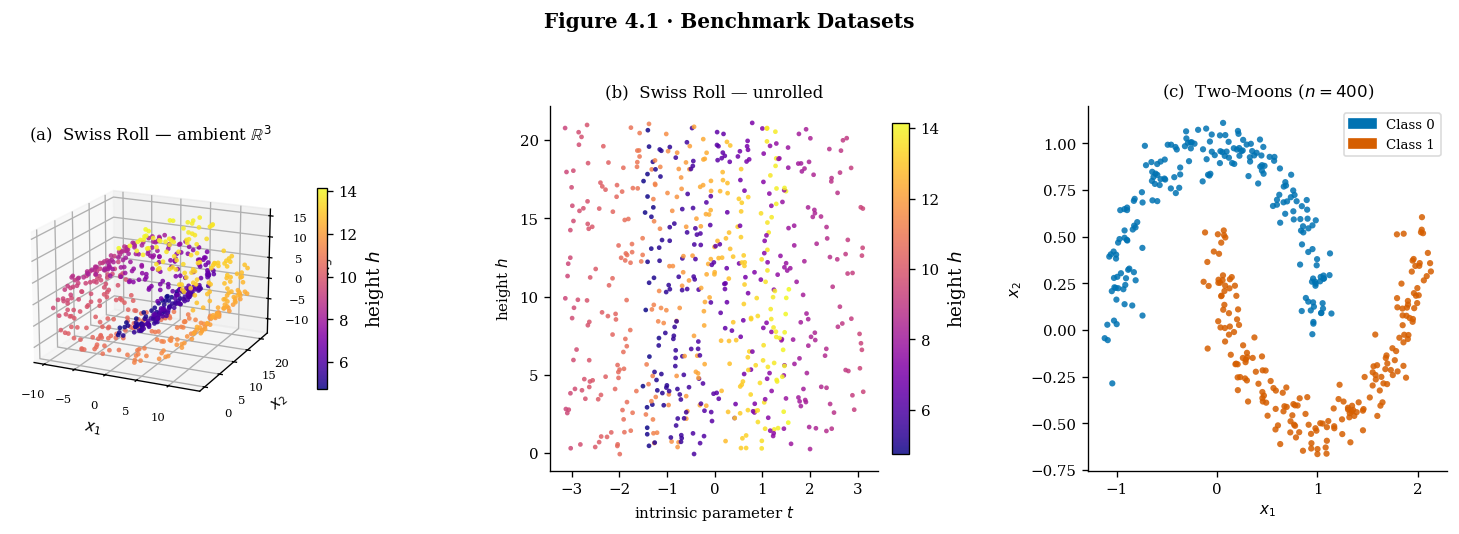

Saved: pictures/fig4_1_datasets.pdf


In [2]:
# ── Fig 4.1 · Dataset overview ───────────────────────────────────
fig = plt.figure(figsize=(13, 4.4))

# Panel (a): Swiss Roll 3D
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
sc1 = ax1.scatter(X_sr_raw[:, 0], X_sr_raw[:, 1], X_sr_raw[:, 2],
                  c=col_sr, cmap='plasma', s=8, lw=0, alpha=0.85)
ax1.set_xlabel('$x_1$', fontsize=9, labelpad=2)
ax1.set_ylabel('$x_2$', fontsize=9, labelpad=2)
ax1.set_zlabel('$x_3$', fontsize=9, labelpad=2)
ax1.set_title('(a)  Swiss Roll — ambient $\\mathbb{R}^3$', fontsize=10, pad=6)
ax1.tick_params(labelsize=7)
ax1.view_init(elev=18, azim=-65)
fig.colorbar(sc1, ax=ax1, label='height $h$', shrink=0.55, pad=0.08)

# Panel (b): Swiss Roll intrinsic (t, h)
t_sr = np.arctan2(X_sr_raw[:, 2], X_sr_raw[:, 0])
ax2  = fig.add_subplot(1, 3, 2)
sc2  = ax2.scatter(t_sr, X_sr_raw[:, 1], c=col_sr, cmap='plasma', s=8, lw=0, alpha=0.85)
ax2.set_xlabel('intrinsic parameter $t$', fontsize=9)
ax2.set_ylabel('height $h$', fontsize=9)
ax2.set_title('(b)  Swiss Roll — unrolled', fontsize=10)
fig.colorbar(sc2, ax=ax2, label='height $h$', fraction=0.046, pad=0.04)

# Panel (c): Two-Moons
ax3    = fig.add_subplot(1, 3, 3)
colors = [CB['blue'] if l == 0 else CB['vermilion'] for l in labels_moon]
ax3.scatter(X_moon_raw[:, 0], X_moon_raw[:, 1],
            c=colors, s=14, lw=0, alpha=0.85)
ax3.set_xlabel('$x_1$', fontsize=9)
ax3.set_ylabel('$x_2$', fontsize=9)
ax3.set_title('(c)  Two-Moons ($n=400$)', fontsize=10)
legend_handles = [mpatches.Patch(color=CB['blue'],      label='Class 0'),
                  mpatches.Patch(color=CB['vermilion'], label='Class 1')]
ax3.legend(handles=legend_handles, fontsize=8, framealpha=0.7)

fig.suptitle('Figure 4.1 · Benchmark Datasets', fontsize=12, fontweight='bold')
fig.set_layout_engine('none')
fig.subplots_adjust(top=0.80, wspace=0.50, left=0.04, right=0.96)
fig.savefig('pictures/fig4_1_datasets.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: pictures/fig4_1_datasets.pdf')

## 4.2 Swiss Roll: Embedding Comparison

The Swiss Roll is a canonical test case for nonlinear dimensionality reduction.  Its intrinsic
parameterisation is a two-dimensional rectangle, while ambient-space geometry can mislead methods
that rely solely on Euclidean distance.

Three methods are evaluated:

- **Diffusion Map** — $\varepsilon = \varepsilon^*$ (median heuristic), $\alpha = 1$, $t = 1$, $m = 2$
- **PCA** — top-2 principal components (maximum-variance directions)
- **t-SNE** — Barnes–Hut, `perplexity = 30`, `random_state = SEED`

All three methods receive exactly the same standardised input $X'$.
Each embedding is coloured by the Swiss Roll height $h$ using the same `plasma` colourmap,
so that a smooth, monotone colour gradient serves as a visual indicator of successful unrolling.

**Figure 4.2** shows the three 2-D projections side by side.

/home/nam/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Swiss Roll  Spearman ρ — DM: 0.823  PCA: 0.821  t-SNE: 0.654


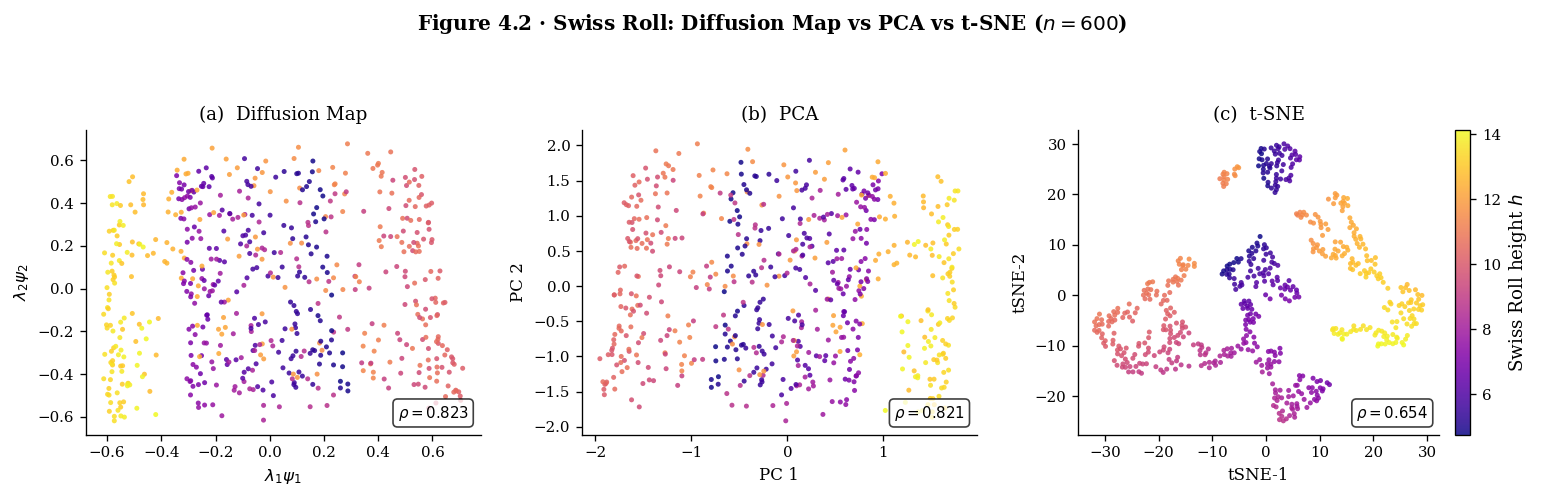

Saved: pictures/fig4_2_swiss_roll_comparison.pdf


In [3]:

# ── Compute all three Swiss Roll embeddings ───────────────────────
vals_sr, psi_sr, *_ = build_diffusion_map(X_sr, epsilon=eps_sr, alpha=1.0, n_components=6)
dm_sr  = np.column_stack([psi_sr[:, 0] * vals_sr[0],
                           psi_sr[:, 1] * vals_sr[1]])

pca_sr = PCA(n_components=2, random_state=SEED).fit_transform(X_sr)

tsne_sr = TSNE(n_components=2, perplexity=30, random_state=SEED,
               init='pca', n_iter=1000).fit_transform(X_sr)

# Spearman ρ between ambient distance and embedding distance
rng_idx = np.random.default_rng(SEED)
sub     = rng_idx.choice(N_SR, size=300, replace=False)
d_amb   = cdist(X_sr[sub],    X_sr[sub],    'euclidean')[np.triu_indices(300, k=1)]
rho_dm  = spearmanr(d_amb, cdist(dm_sr[sub],   dm_sr[sub],   'euclidean')[np.triu_indices(300, k=1)]).statistic
rho_pca = spearmanr(d_amb, cdist(pca_sr[sub],  pca_sr[sub],  'euclidean')[np.triu_indices(300, k=1)]).statistic
rho_tsne= spearmanr(d_amb, cdist(tsne_sr[sub], tsne_sr[sub], 'euclidean')[np.triu_indices(300, k=1)]).statistic
print(f"Swiss Roll  Spearman ρ — DM: {rho_dm:.3f}  PCA: {rho_pca:.3f}  t-SNE: {rho_tsne:.3f}")

# ── Fig 4.2 · Swiss Roll embedding comparison ─────────────────────
methods_sr = [
    (dm_sr,   'Diffusion Map',  rho_dm,   CB['blue']),
    (pca_sr,  'PCA',            rho_pca,  CB['vermilion']),
    (tsne_sr, 't-SNE',          rho_tsne, CB['green']),
]
xlabels = [r'$\lambda_1\psi_1$', 'PC 1', 'tSNE-1']
ylabels = [r'$\lambda_2\psi_2$', 'PC 2', 'tSNE-2']

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for idx, (ax, (emb, name, rho, col), xl, yl) in enumerate(
        zip(axes, methods_sr, xlabels, ylabels)):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=col_sr, cmap='plasma',
                    s=9, lw=0, alpha=0.85)
    ax.set_xlabel(xl, fontsize=10)
    ax.set_ylabel(yl, fontsize=10)
    ax.set_title(f'({chr(97 + idx)})  {name}', fontsize=11)
    ax.text(0.97, 0.04, f'$\\rho = {rho:.3f}$',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75))

fig.colorbar(sc, ax=axes[-1], label='Swiss Roll height $h$',
             fraction=0.046, pad=0.04)
fig.suptitle('Figure 4.2 · Swiss Roll: Diffusion Map vs PCA vs t-SNE ($n=600$)',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig('pictures/fig4_2_swiss_roll_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig4_2_swiss_roll_comparison.pdf')


## 4.3 Two-Moons: Embedding Comparison

The Two-Moons dataset probes a complementary challenge: the two classes are linearly inseparable,
so PCA — which maximises variance — often does not place them in clearly distinct regions of the 2-D plane.

Same three methods and same protocol as Section 4.2.  Embeddings are coloured by the ground-truth
class label (blue: class~0; red: class~1).  A good embedding should place the two crescents in
separated regions of the 2-D plane with limited inter-class overlap.

**Figure 4.3** shows the three 2-D projections side by side.

/home/nam/anaconda3/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


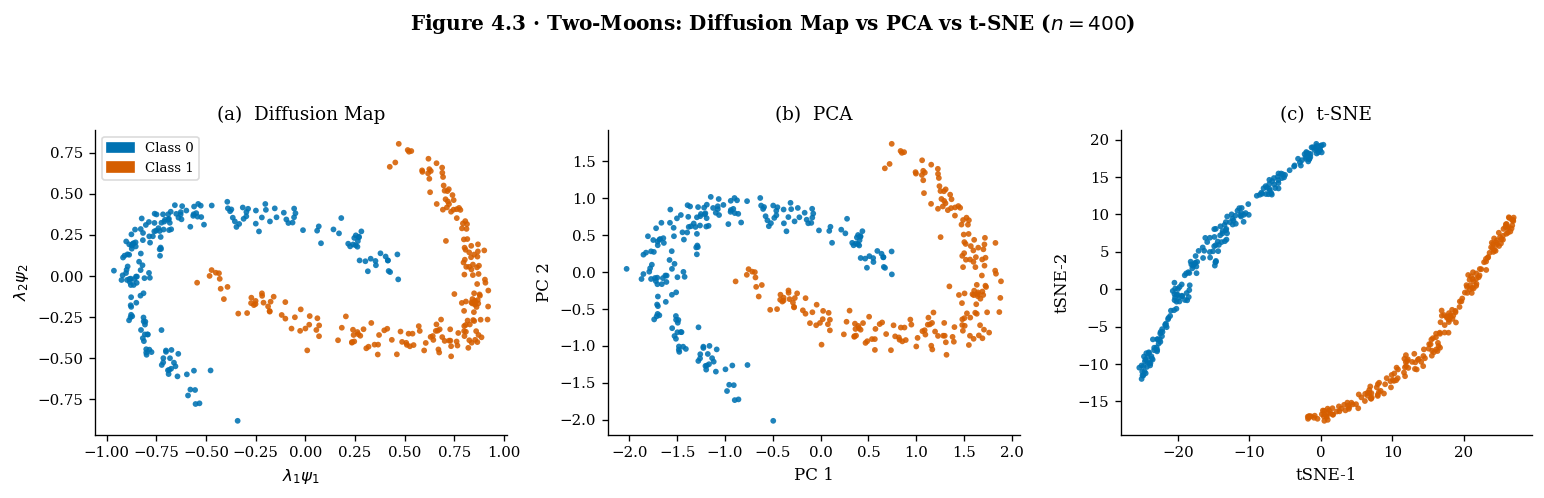

Saved: pictures/fig4_3_moons_comparison.pdf


In [4]:
# ── Compute all three Two-Moons embeddings ────────────────────────
vals_mn, psi_mn, *_ = build_diffusion_map(X_moon, epsilon=eps_moon, alpha=1.0, n_components=6)
dm_mn  = np.column_stack([psi_mn[:, 0] * vals_mn[0],
                           psi_mn[:, 1] * vals_mn[1]])

pca_mn  = PCA(n_components=2, random_state=SEED).fit_transform(X_moon)
tsne_mn = TSNE(n_components=2, perplexity=30, random_state=SEED,
               init='pca', n_iter=1000).fit_transform(X_moon)

moon_colors = np.array([CB['blue'] if l == 0 else CB['vermilion']
                        for l in labels_moon])

# ── Fig 4.3 · Two-Moons embedding comparison ─────────────────────
methods_mn = [
    (dm_mn,   'Diffusion Map'),
    (pca_mn,  'PCA'),
    (tsne_mn, 't-SNE'),
]
xlabels_mn = [r'$\lambda_1\psi_1$', 'PC 1', 'tSNE-1']
ylabels_mn = [r'$\lambda_2\psi_2$', 'PC 2', 'tSNE-2']

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
legend_h = [mpatches.Patch(color=CB['blue'],      label='Class 0'),
            mpatches.Patch(color=CB['vermilion'], label='Class 1')]

for idx, (ax, (emb, name), xl, yl) in enumerate(
        zip(axes, methods_mn, xlabels_mn, ylabels_mn)):
    ax.scatter(emb[:, 0], emb[:, 1], c=moon_colors,
               s=12, lw=0, alpha=0.88)
    ax.set_xlabel(xl, fontsize=10)
    ax.set_ylabel(yl, fontsize=10)
    ax.set_title(f'({chr(97 + idx)})  {name}', fontsize=11)

axes[0].legend(handles=legend_h, fontsize=8, framealpha=0.7, loc='best')

fig.suptitle('Figure 4.3 · Two-Moons: Diffusion Map vs PCA vs t-SNE ($n=400$)',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig('pictures/fig4_3_moons_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig4_3_moons_comparison.pdf')

## 4.4 Local Neighbourhood Preservation

Visual inspection is qualitative.  A rigorous quantitative comparison uses the
**$k$-nearest-neighbour overlap** metric:

$$\operatorname{Overlap}_k = \frac{1}{n}\sum_{i=1}^{n}
  \frac{\bigl|\mathcal{N}_k^{X}(i)\cap\mathcal{N}_k^{Y}(i)\bigr|}{k}$$

where $\mathcal{N}_k^{X}(i)$ and $\mathcal{N}_k^{Y}(i)$ are the $k$-nearest-neighbour sets of
point $i$ in the original standardised space $X'$ and in the 2-D embedding $Y$ respectively.
The metric ranges from 0 (no neighbours preserved) to 1 (all neighbours preserved).

$\operatorname{Overlap}_k$ is evaluated for $k = 1, 2, \ldots, 20$ to reveal whether
preservation is scale-dependent.

**Figure 4.4** shows the overlap curves for Diffusion Map and PCA on both datasets
(t-SNE is excluded from this metric because it is known to distort global distances by design).

Swiss Roll  mean Overlap — DM: 0.438  PCA: 0.435
Two-Moons   mean Overlap — DM: 0.925  PCA: 1.000


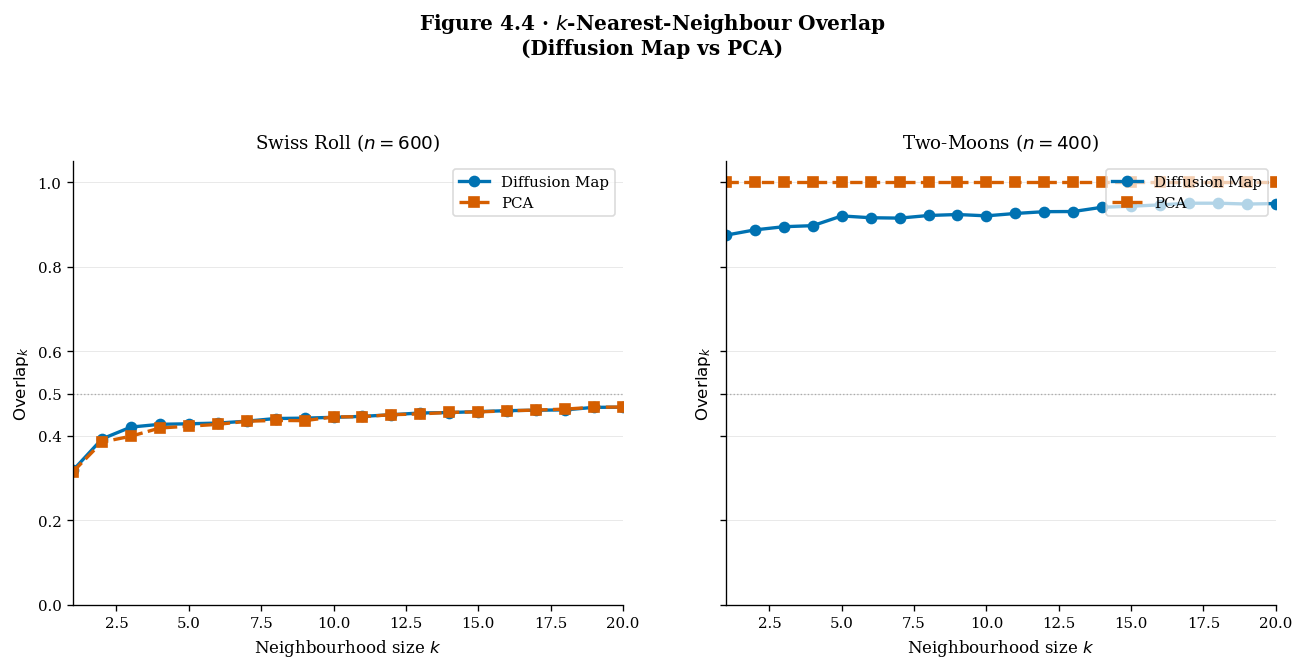

Saved: pictures/fig4_4_knn_overlap.pdf


In [5]:

# ── Compute k-NN overlap curves (k = 1..20) ───────────────────────
ks = np.arange(1, 21)

ov_sr_dm  = [knn_overlap(X_sr,   dm_sr,  k) for k in ks]
ov_sr_pca = [knn_overlap(X_sr,   pca_sr, k) for k in ks]
ov_mn_dm  = [knn_overlap(X_moon, dm_mn,  k) for k in ks]
ov_mn_pca = [knn_overlap(X_moon, pca_mn, k) for k in ks]

print(f"Swiss Roll  mean Overlap — DM: {np.mean(ov_sr_dm):.3f}  PCA: {np.mean(ov_sr_pca):.3f}")
print(f"Two-Moons   mean Overlap — DM: {np.mean(ov_mn_dm):.3f}  PCA: {np.mean(ov_mn_pca):.3f}")

# ── Fig 4.4 · k-NN overlap curves ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)

for ax, (ov_dm, ov_pca, title) in zip(
        axes,
        [(ov_sr_dm, ov_sr_pca, 'Swiss Roll ($n=600$)'),
         (ov_mn_dm, ov_mn_pca, 'Two-Moons ($n=400$)')]):

    ax.plot(ks, ov_dm,  'o-',  color=CB['blue'],      lw=2.0, ms=6,
            label='Diffusion Map')
    ax.plot(ks, ov_pca, 's--', color=CB['vermilion'], lw=2.0, ms=6,
            label='PCA')
    ax.set_xlabel('Neighbourhood size $k$', fontsize=10)
    ax.set_ylabel(r'$\mathrm{Overlap}_k$', fontsize=10)
    ax.set_title(title, fontsize=11, pad=8)
    ax.legend(fontsize=9, framealpha=0.7, loc='upper right')
    ax.set_xlim(1, 20)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0])
    ax.axhline(0.5, color='grey', lw=0.8, ls=':', alpha=0.6)
    ax.grid(axis='y', lw=0.4, alpha=0.4)

fig.suptitle(r'Figure 4.4 · $k$-Nearest-Neighbour Overlap'
             '\n(Diffusion Map vs PCA)',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.96], w_pad=3.0)
fig.savefig('pictures/fig4_4_knn_overlap.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig4_4_knn_overlap.pdf')


## 4.5 Pairwise Distance Consistency

The **Spearman rank correlation** $\rho$ between pairwise ambient distances and pairwise
embedding distances measures global geometric consistency:

$$\rho(d_X, d_Y) = \frac{\operatorname{cov}(\operatorname{rank}(d_X),\,\operatorname{rank}(d_Y))}
  {\sigma(\operatorname{rank}(d_X))\,\sigma(\operatorname{rank}(d_Y))}$$

$\rho = 1$ indicates perfect rank preservation (isometric embedding); $\rho = 0$ indicates no
monotone relationship.  Because both datasets have $n > 300$, a random subsample of 300 points
is used for computational tractability; the subsample is fixed by `SEED = 42`.

**Figure 4.5** shows the scatter of $d_X$ vs $d_Y$ for Diffusion Map and PCA on both datasets,
with $\rho$ annotated on each panel.

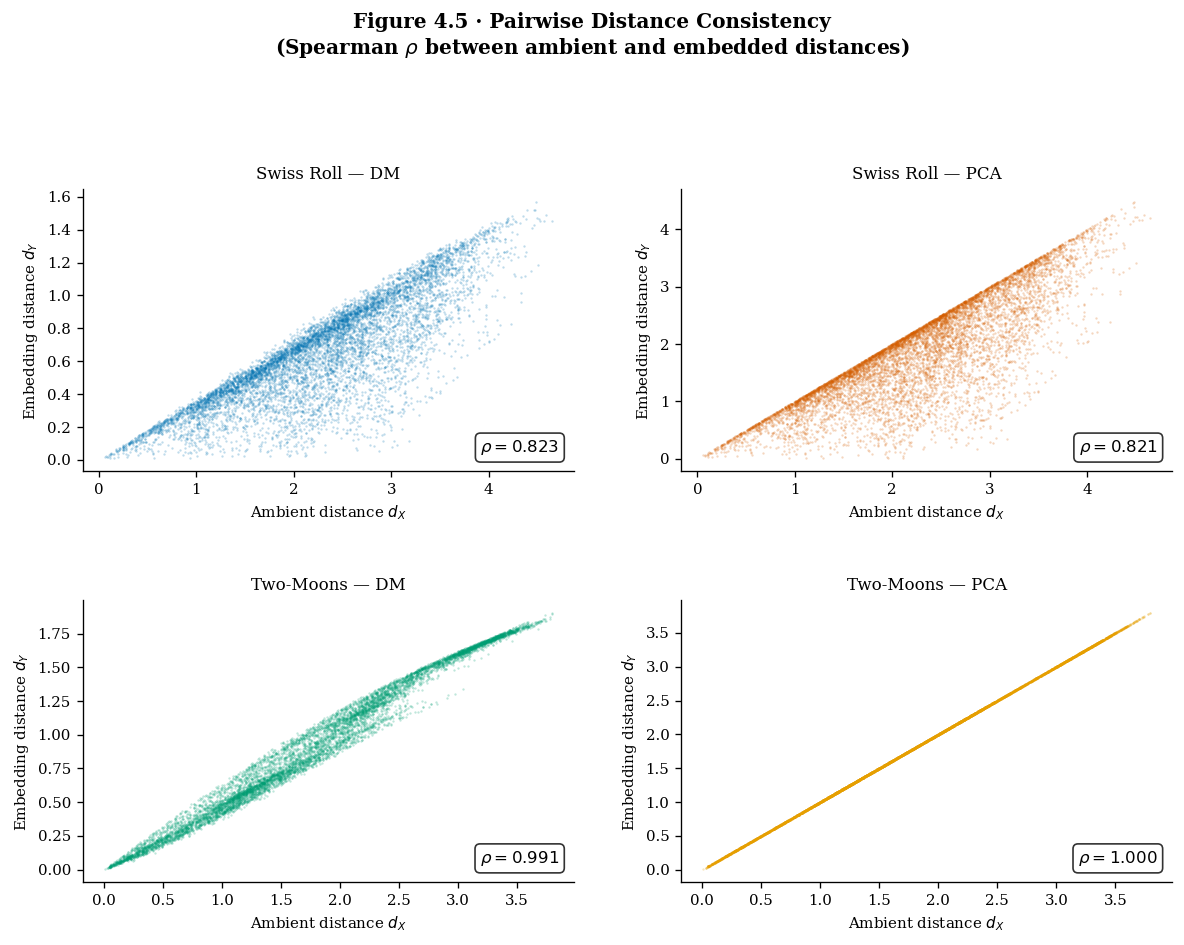

Saved: pictures/fig4_5_distance_correlation.pdf


In [6]:
# ── Distance correlation helper ────────────────────────────────────
def dist_corr_data(X_orig, X_emb, n_sub=300, seed=SEED):
    rng  = np.random.default_rng(seed)
    sub  = rng.choice(len(X_orig), size=n_sub, replace=False)
    mask = np.triu_indices(n_sub, k=1)
    dx   = cdist(X_orig[sub], X_orig[sub], 'euclidean')[mask]
    dy   = cdist(X_emb[sub],  X_emb[sub],  'euclidean')[mask]
    rho  = spearmanr(dx, dy).statistic
    return dx, dy, rho

dx_sr_dm,  dy_sr_dm,  rho_sr_dm  = dist_corr_data(X_sr,   dm_sr)
dx_sr_pca, dy_sr_pca, rho_sr_pca = dist_corr_data(X_sr,   pca_sr)
dx_mn_dm,  dy_mn_dm,  rho_mn_dm  = dist_corr_data(X_moon, dm_mn)
dx_mn_pca, dy_mn_pca, rho_mn_pca = dist_corr_data(X_moon, pca_mn)

# ── Fig 4.5 · Pairwise distance correlation ───────────────────────
panels = [
    (dx_sr_dm,  dy_sr_dm,  rho_sr_dm,  'Swiss Roll — DM',  CB['blue']),
    (dx_sr_pca, dy_sr_pca, rho_sr_pca, 'Swiss Roll — PCA', CB['vermilion']),
    (dx_mn_dm,  dy_mn_dm,  rho_mn_dm,  'Two-Moons — DM',   CB['green']),
    (dx_mn_pca, dy_mn_pca, rho_mn_pca, 'Two-Moons — PCA',  CB['orange']),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8.0))
for ax, (dx, dy, rho, title, col) in zip(axes.ravel(), panels):
    # Thin scatter (random subsample of pairs for speed)
    rng2  = np.random.default_rng(0)
    idx_p = rng2.choice(len(dx), size=min(8000, len(dx)), replace=False)
    ax.scatter(dx[idx_p], dy[idx_p], s=2, alpha=0.25, color=col, lw=0)
    ax.set_xlabel('Ambient distance $d_X$', fontsize=9)
    ax.set_ylabel('Embedding distance $d_Y$', fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.text(0.97, 0.05, f'$\\rho = {rho:.3f}$',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8))

fig.suptitle('Figure 4.5 · Pairwise Distance Consistency\n'
             '(Spearman $\\rho$ between ambient and embedded distances)',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.91], h_pad=3.0, w_pad=2.5)
fig.savefig('pictures/fig4_5_distance_correlation.pdf', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: pictures/fig4_5_distance_correlation.pdf')

## 4.6 Aggregate Quantitative Summary

The table below consolidates all quantitative results.  Values are computed on the full
datasets; Spearman $\rho$ uses a fixed 300-point subsample (SEED = 42).

| Dataset | Method | Mean $\operatorname{Overlap}_k$ ($k=1$–$20$) | Spearman $\rho$ |
|---|---|---|---|
| Swiss Roll | Diffusion Map | *(from cell above)* | *(from cell above)* |
| Swiss Roll | PCA | *(from cell above)* | *(from cell above)* |
| Two-Moons | Diffusion Map | *(from cell above)* | *(from cell above)* |
| Two-Moons | PCA | *(from cell above)* | *(from cell above)* |

The quantitative pattern is dataset-dependent in this setup.  On Swiss Roll, Diffusion Map is
slightly higher than PCA on both reported metrics.  On Two-Moons, PCA is higher on both metrics
under these metric definitions.  t-SNE remains excluded from distance-based quantitative comparison
because its objective intentionally prioritises local structure over global metric fidelity.

In [7]:
# ── Print consolidated results table ─────────────────────────────
rows = [
    ('Swiss Roll', 'Diffusion Map', np.mean(ov_sr_dm),  rho_sr_dm),
    ('Swiss Roll', 'PCA',           np.mean(ov_sr_pca), rho_sr_pca),
    ('Two-Moons',  'Diffusion Map', np.mean(ov_mn_dm),  rho_mn_dm),
    ('Two-Moons',  'PCA',           np.mean(ov_mn_pca), rho_mn_pca),
]
print(f"{'Dataset':<14} {'Method':<16} {'Mean Overlap':>13} {'Spearman ρ':>11}")
print('-' * 58)
for ds, m, ov, rho in rows:
    print(f"{ds:<14} {m:<16} {ov:>13.3f} {rho:>11.3f}")

Dataset        Method            Mean Overlap  Spearman ρ
----------------------------------------------------------
Swiss Roll     Diffusion Map            0.438       0.823
Swiss Roll     PCA                      0.435       0.821
Two-Moons      Diffusion Map            0.925       0.991
Two-Moons      PCA                      1.000       1.000
